<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/04_gis_with_python/08_overlay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6.8 Overlay vectorial (resumen)

Resumen del capítulo *Vector overlay operations* de *Python for Geographic Data Analysis* (Tenkanen et al., pythongis.org), reducido a lo que se usa en el TFG. El libro usa datos de Helsinki; aquí se usan tus datos de Asturias.

**Idea clave:** el overlay combina dos capas de **polígonos** y **corta las geometrías** por donde se cruzan. Es la diferencia con `sjoin`, que solo empareja filas y no modifica las geometrías. Sirve para preguntas de **superficie**, como *«¿qué parte de cada concejo está a menos de 5 km de una farmacia?»*.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# Folder that contains raw/ and asturias_miteco.gpkg. In Colab, e.g. Path("/content/drive/MyDrive/tfg/datos").
DATA_DIR = Path("/content/drive/MyDrive/tfg/")
CRS_METRES = "EPSG:25830"


def load_layer(pattern):
    """Read the latest raw download matching a pattern and reproject it to metres."""
    path = sorted(DATA_DIR.glob(f"sitpa_raw_data/{pattern}"))[-1]
    return gpd.read_file(path).to_crs(CRS_METRES)


municipalities = gpd.read_file(DATA_DIR / "miteco_data/out/asturias_miteco.gpkg").to_crs(CRS_METRES)
pharmacies = load_layer("farmacias_botiquines__farmacias_*.geojson")

# Area within 5 km (straight line) of any pharmacy, as a one-row GeoDataFrame
covered = gpd.GeoDataFrame(geometry=[pharmacies.buffer(5000).union_all()], crs=CRS_METRES)

## Las operaciones

`left.overlay(right, how=...)`

| `how` | Resultado | Pregunta del TFG |
|---|---|---|
| `"intersection"` | solo las partes comunes a las dos capas | parte de cada concejo **con** farmacia a ≤ 5 km |
| `"difference"` | partes de `left` que **no** están en `right` | parte de cada concejo **sin** farmacia a ≤ 5 km |
| `"union"` | todo, cortado por los cruces | rara vez necesaria |
| `"symmetric_difference"`, `"identity"` | variantes de las anteriores | no previstas |

El resultado conserva los atributos de las dos capas (en `difference`, solo los de `left`). El CRS tiene que ser el mismo.

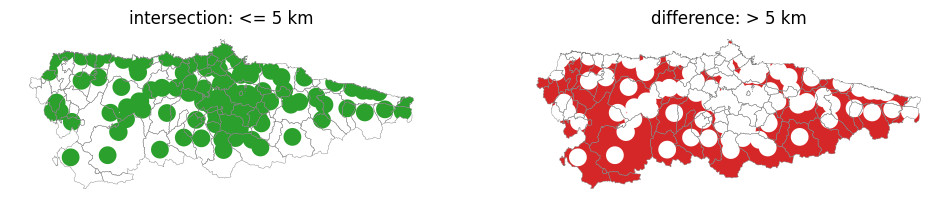

In [3]:
covered_part = municipalities[["nombre", "geometry"]].overlay(covered, how="intersection")
uncovered_part = municipalities[["nombre", "geometry"]].overlay(covered, how="difference")

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 3))
covered_part.plot(ax=ax1, color="tab:green")
uncovered_part.plot(ax=ax2, color="tab:red")
for ax, title in [(ax1, "intersection: <= 5 km"), (ax2, "difference: > 5 km")]:
    municipalities.boundary.plot(ax=ax, color="gray", linewidth=0.3)
    ax.set_title(title)
    ax.set_axis_off()

## Uso típico: porcentaje de superficie cubierta por concejo
Las áreas se calculan **después** de cortar. Como el CRS está en metros, `.area` da m².

In [4]:
area_total = municipalities.set_index("nombre").area
area_covered = covered_part.set_index("nombre").area.groupby(level=0).sum()  # a municipality may be split into several pieces

coverage = (area_covered.reindex(area_total.index, fill_value=0) / area_total * 100).round(1)
coverage.sort_values().head(8)

,0
nombre,
Illano,0.0
Degaña,0.0
San Tirso de Abres,0.0
Yernes y Tameza,0.0
Sobrescobio,0.1
Caravia,1.7
Taramundi,1.9
Ponga,2.0


⚠️ **Esto es superficie, no población.** Un concejo con el 40 % de su superficie cubierta puede tener cubierta al 95 % de su población si la gente vive cerca de la capital. Para hablar de acceso de la población se necesitan los núcleos con habitantes (6.7) y no el área.

## `clip`: recortar una capa por otra
`gpd.clip(capa, mascara)` recorta y conserva **solo los atributos de la capa**. Es lo más práctico para quedarse con lo que cae dentro de Asturias, por ejemplo al descargar carreteras de OSM con un margen.

In [5]:
asturias = municipalities.union_all()
clipped = gpd.clip(covered, asturias)  # the 5 km circles go beyond the coastline and the regional border
print(f"before: {covered.area.sum() / 1e6:,.0f} km2 | after clipping to Asturias: {clipped.area.sum() / 1e6:,.0f} km2")

before: 6,182 km2 | after clipping to Asturias: 5,523 km2


## Lo que se ha omitido del capítulo
- `union`, `symmetric_difference` e `identity` con ejemplos y figuras: la tabla basta.
- La función auxiliar de dibujo del libro.

Documentación: https://geopandas.org/en/stable/docs/user_guide/set_operations.html